## Multiple Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
ds = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
ds.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
print(ds['NObeyesdad'].unique())

['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


In [5]:
category = {
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}

In [6]:
ds['NObeyesdad'] = ds['NObeyesdad'].map(category).fillna(-1).astype(int)

In [7]:
for col in ds.select_dtypes(include=["object"]).columns:
    ds[col] = ds[col].astype("category").cat.codes

In [8]:
X = ds[["Age", "Height"]].values  
X = np.c_[np.ones(X.shape[0]), X]  
Y = ds["NObeyesdad"].values

In [9]:
theta = np.linalg.pinv(X.T @ X) @ X.T @ Y
Yp = X @ theta

In [10]:
print("Regression Coefficients:", theta)

Regression Coefficients: [-4.17194429  0.08964216  2.99985154]


Text(0.5, 1.0, 'Height vs NObeyesdad')

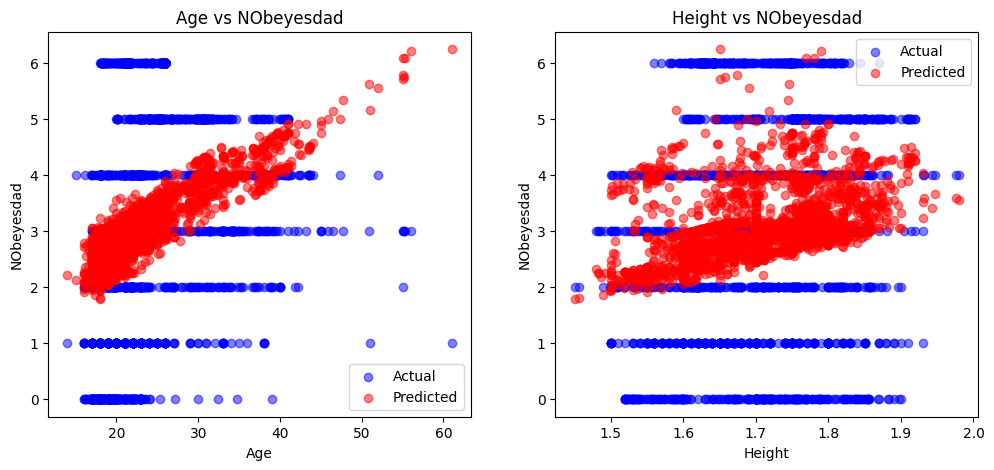

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(ds["Age"], ds["NObeyesdad"], label="Actual", color="blue", alpha=0.5)
axs[0].scatter(ds["Age"], Yp, label="Predicted", color="red", alpha=0.5)
axs[0].set_xlabel("Age")
axs[0].set_ylabel("NObeyesdad")
axs[0].legend()
axs[0].set_title("Age vs NObeyesdad")

axs[1].scatter(ds["Height"], ds["NObeyesdad"], label="Actual", color="blue", alpha=0.5)
axs[1].scatter(ds["Height"], Yp, label="Predicted", color="red", alpha=0.5)
axs[1].set_xlabel("Height")
axs[1].set_ylabel("NObeyesdad")
axs[1].legend()
axs[1].set_title("Height vs NObeyesdad")